# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [67]:
STUDENT_NAME = 'Басараб Дмитрій'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 1     # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 1, файл lr6_варіант_01.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [68]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [69]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [70]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: бо класифікує чи піде чи ні

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність:
#відтік 0    848 1    352 для точності класи незбалансовані
#повнота важлива де пропуск коштує дорого

CV_SCHEME = '5 кратна крос валідація'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: основний варіант, даних достатньо

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')


рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [71]:
raw = pd.read_csv(DATA, encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())
print(raw.value_counts("відтік"))

розмір: (1200, 26)
частка відтоку: 0.293

типи стовпців: {'str': 13, 'float64': 7, 'int64': 6}
відтік
0    848
1    352
Name: count, dtype: int64


In [72]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.

print("«стовпець | тип | унікальних | % пропусків | приклад»")
data = []
for col in raw.columns:
    data.append({
        "стовпець": col,
        "тип": raw[col].dtype,
        "унікальних": raw[col].nunique(),
        "% пропусків": len(raw[col].dropna())/len(raw[col])*100,
        "приклад": raw[col].dropna().iloc[1]
    })
    #data[col] = [col,raw[col].dtype,len(raw[col].unique()),len(raw[col].notna())/len(raw[col])*100,raw[col].iloc[1]]

df = pd.DataFrame(data)
df.sort_values("% пропусків")

«стовпець | тип | унікальних | % пропусків | приклад»


,стовпець,тип,унікальних,% пропусків,приклад
23,код_причини_закриття,str,5,29.333333,ЯКІ-03
22,сума_повернення_депозиту,float64,351,29.333333,31.41
17,середній_час_відповіді_хв,float64,264,66.250000,4.0
14,трафік_ГБ,str,974,95.000000,166.3
12,щомісячний_платіж,str,1129,96.000000,366.93
16,аварій_на_ділянці_за_квартал,float64,6,97.000000,1.0
0,id_клієнта,str,1200,100.000000,K10001
1,вік,float64,63,100.000000,39.0
7,спосіб_оплати,str,3,100.000000,картка
6,тип_підключення,str,3,100.000000,оптика


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [73]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----
#щомісячний платіж str
#трафік має str отже в них є дати замість float

for col in ["трафік_ГБ", "щомісячний_платіж"]:
    # Пробуємо перетворити на числа; усе, що не вийде, стане NaN
    numeric_col = pd.to_numeric(raw[col], errors="coerce")
    
    # Беремо рядки, де було значення, але воно не стало числом
    bad_rows = raw[raw[col].notna() & numeric_col.isna()][[col]]
    
    print(f"=== Проблемні значення у '{col}' (всього: {len(bad_rows)}) ===")
    print(bad_rows.head(5), "\n")

raw.iloc[72]

mask = pd.to_datetime(
    raw["трафік_ГБ"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
).notna()

print(raw.loc[mask, ["id_клієнта", "трафік_ГБ"]])
#всі до 100 відсотків окрім щомісячного платежа(тре уточнити чому не було) бо не було повернень, аварій і дзвінків

=== Проблемні значення у 'трафік_ГБ' (всього: 2) ===
               трафік_ГБ
444  1900-01-25 00:00:00
910  1900-01-15 00:00:00 

=== Проблемні значення у 'щомісячний_платіж' (всього: 27) ===
    щомісячний_платіж
72         393.67 грн
118        426.37 грн
128        331.12 грн
289        369.93 грн
307        341.36 грн 

    id_клієнта            трафік_ГБ
444     K10444  1900-01-25 00:00:00
910     K10910  1900-01-15 00:00:00


In [74]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'    # назва стовпця
PROBLEM_MNAR           = 'код_причини_закриття'    # назва стовпця
MNAR_MEANING           = 'означає шо цей пропуск не є просто так, значить не існувало в той момент значення взагалі'    # що означає сам факт пропуску, одним реченням

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [75]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        # ----- ВАШ КОД -----
        # 1) None / NaN            -> np.nan
        if v is None or isinstance(v,(datetime.datetime,pd.Timestamp)):
            return np.nan
        # 2) datetime / Timestamp  -> np.nan   (це брак, а не дані)
        # 3) число                 -> float
        if isinstance(v, (int, float, np.integer, np.floating)):
            return float(v)
        # 4) текст                 -> перше число в ньому, інакше np.nan
        m = re.search(r'-?\d+(?:[.,]\d+)?', str(v).replace(',', '.'))
        return float(m.group()) if m else np.nan
        raise NotImplementedError
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')
to_number(pd.Series(["dff"]))
raw

to_number працює


,id_клієнта,вік,стать,місто,філія,тариф,тип_підключення,спосіб_оплати,автоплатіж,кількість_послуг,місяців_обслуговування,швидкість_тарифу_Мбіт,щомісячний_платіж,знижка_відсоток,трафік_ГБ,кількість_звернень_у_підтримку,аварій_на_ділянці_за_квартал,середній_час_відповіді_хв,річний_платіж,код_тарифного_плану,індекс_лояльності_CRM,дата_підключення,сума_повернення_депозиту,код_причини_закриття,кількість_дзвінків_утримання,відтік
0,K10000,45.0,ч,Стрий,Ф-02 Захід,Базовий,оптика,картка,ні,2,41.0,100,270.14,20,101.3,2,0.0,25.7,3200.0,КОД-015,217.306,2023-10-03,NaN,NaN,0,0
1,K10001,39.0,ч,Львів,Ф-04 Південь,Базовий,оптика,картка,так,2,17.0,600,366.93,20,166.3,3,1.0,4.0,4379.7,КОД-021,740.521,2024-12-19,NaN,NaN,0,0
2,K10002,26.0,ч,Самбір,Ф-05 Північ,Максимальний,оптика,каса,ні,1,17.0,500,374.29,10,242.5,2,1.0,13.7,4541.3,КОД-037,857.359,2023-01-20,NaN,NaN,0,0
3,K10003,48.0,жін,Золочів,Ф-02 Захід,Базовий,оптика,картка,так,3,12.0,400,355.38,10,123.1,3,1.0,6.8,4274.5,КОД-029,213.054,2024-04-16,121.49,ПЕР-04,0,1
4,K10004,20.0,ч,Львів,Ф-04 Південь,Базовий,оптика,картка,так,1,14.0,200,245.76,0,353.5,0,0.0,NaN,2972.7,КОД-011,846.947,2023-10-24,NaN,NaN,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,K11195,46.0,ж,Дрогобич,Ф-01 Центр,Базовий,оптика,картка,так,2,11.0,400,305.87,10,37.3,0,1.0,NaN,3718.7,КОД-020,966.376,2024-05-20,NaN,NaN,0,0
1196,K11196,49.0,ж,Стрий,Ф-02 Захід,Оптимальний,оптика,каса,ні,1,11.0,300,287.15,0,196.4,2,0.0,12.1,3465.4,КОД-027,571.267,2023-02-20,NaN,NaN,0,0
1197,K11197,31.0,Ж,Львів,Ф-02 Захід,Базовий,оптика,каса,так,3,10.0,1000,374.71,10,21.8,0,1.0,NaN,4451.4,КОД-028,878.332,2024-09-24,132.94,ЦІН-02,2,1
1198,K11198,31.0,ж,Львів,Ф-06 Приміська,Базовий,оптика,картка,так,3,14.0,100,297.04,10,164.9,1,1.0,3.6,3527.9,КОД-001,270.565,2024-06-18,221.02,ПЕР-01,2,1


In [76]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        # ----- ВАШ КОД -----
        s = d[c]
        def clean_sex(s):
                    m = {'ч': 'ч', 'чол': 'ч', 'ж': 'ж', 'жін': 'ж'}
                    return s.astype(str).str.strip().str.lower().map(lambda x: m.get(x, np.nan))
        if c == "стать":
            s = clean_sex(s)
        # дата_підключення -> число (день);
        if c == "дата_підключення":
            dta = pd.to_datetime(s, errors='coerce')
            X["день_підключення"] = dta.dt.day.astype(float)
            log.append({
                'ознака': 'день_підключення', 
                'тип': 'дата -> дні (float)', 
                'пропуски': int(X["день_підключення"].isna().sum())
            })
            continue
        elif pd.api.types.is_numeric_dtype(s):
            X[c] = s.astype(float)
            тип = 'числова -> float'
            
        # 3. текстова / змішана колонка
        else:
            vals = to_number(s)
            non_null = s.notna().sum()
            ratio = (vals.notna().sum() / non_null) if non_null > 0 else 0.0
            
            # Якщо >80% розбираються в число -> число
            if ratio > 0.8:
                X[c] = vals.astype(float)
                тип = f'текст -> float ({ratio:.0%})'
            # Інша текстова -> category (приводимо регістр і пробіли)
            else:
                X[c] = s.astype('string').str.strip().str.lower().astype('category')
                тип = 'текст -> category'
                
        # Тепер X[c] точно існує, помилки KeyError не буде
        log.append({'ознака': c, 'тип': тип, 'пропуски': int(X[c].isna().sum())})
        #raise NotImplementedError
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)
print(X_all.columns)

матриця ознак: (1200, 24)
категоріальних: 6


,ознака,тип,пропуски
0,вік,числова -> float,0
1,стать,текст -> category,0
2,місто,текст -> category,0
3,філія,текст -> float (100%),0
4,тариф,текст -> category,0
5,тип_підключення,текст -> category,0
6,спосіб_оплати,текст -> category,0
7,автоплатіж,текст -> category,0
8,кількість_послуг,числова -> float,0
9,місяців_обслуговування,числова -> float,0


Index(['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж',
       'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'код_тарифного_плану', 'індекс_лояльності_CRM',
       'день_підключення', 'сума_повернення_депозиту', 'код_причини_закриття', 'кількість_дзвінків_утримання'],
      dtype='str')


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [77]:
def make_pipe(X, clf):
    # ----- ВАШ КОД -----
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    num = [c for c in X.columns if c not in cat]
    
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False))]), cat),
    ])
    
    return Pipeline([
        ('prep', prep),
        ('clf', clf),
    ])
    #raise NotImplementedError


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())
_p

конвеєр зібрано, пробний прогін AUC 0.917


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of

---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [78]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.917 ± 0.018
час      : 2.2 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [79]:
FIRST_REACTION = 'дуже високий AUC може означати про помилку.0,9–1,0	або задача справді проста, або в даних є витік'
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

дуже високий AUC може означати про помилку.0,9–1,0	або задача справді проста, або в даних є витік


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [80]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        miss = d[c].isna()
        if miss.sum() < min_group or (~miss).sum() < min_group:
                continue
        auc = roc_auc_score(y, d[c].notna().astype(int))

        rows.append({"ознака":c,"частка_заповнено":len(d[c].dropna()),"частка_не_заповнено":d[c].isna().sum(),"показник":auc})
        # але рахувати його можна лише якщо обидві групи більші за min_group
        #raise NotImplementedError
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,частка_заповнено,частка_не_заповнено,показник
4,сума_повернення_депозиту,352,848,1.000000
5,код_причини_закриття,352,848,1.000000
3,середній_час_відповіді_хв,795,405,0.549850
0,щомісячний_платіж,1152,48,0.496141
1,трафік_ГБ,1140,60,0.491156
2,аварій_на_ділянці_за_квартал,1164,36,0.489065


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [81]:
TARGET_LEAK = [
    # 'назва_стовпця',   # чому його немає в момент прогнозу
    "код_причини_закриття",
    "сума_повернення_депозиту"
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['код_причини_закриття', 'сума_повернення_депозиту']


In [82]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.913 ± 0.016


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [83]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'код_тарифного_плану', 'індекс_лояльності_CRM', 'день_підключення', 'кількість_дзвінків_утримання']


In [84]:
HUMAN_LEAK = [
    # 'назва_стовпця',   # ким і КОЛИ заповнюється це поле
    "кількість_дзвінків_утримання"
]
HUMAN_LEAK_WHY = 'можливо значення не корелювали'      # чому детектор із 5.1 його не спіймав

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.822 ± 0.031


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

філія -6.0
Частка відтоку 23.14814814814815 %
філія -5.0
Частка відтоку 23.0 %
філія -4.0
Частка відтоку 23.863636363636363 %
філія -3.0
Частка відтоку 17.171717171717173 %
філія -2.0
Частка відтоку 46.22641509433962 %
філія -1.0
Частка відтоку 41.41414141414141 %


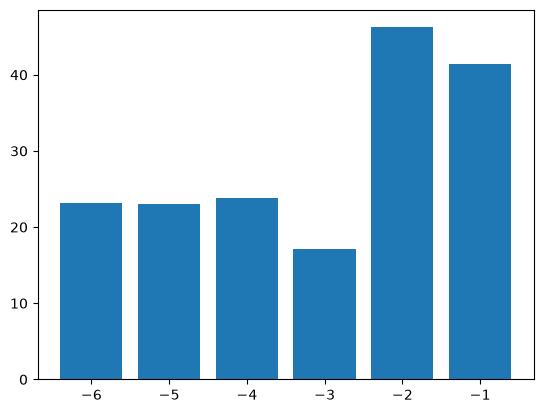

квартал частка відтоку
1 27.56183745583039 %
квартал частка відтоку
2 29.39297124600639 %
квартал частка відтоку
3 28.859060402684563 %
квартал частка відтоку
4 31.372549019607842 %


<BarContainer object of 4 artists>

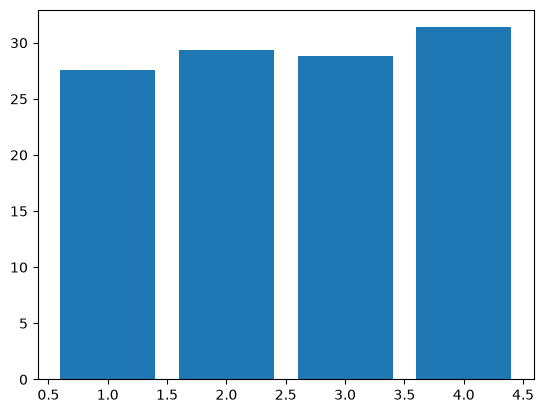

In [85]:
# ----- ВАШ КОД -----
# 1) частка відтоку за кожною філією (і скільки клієнтів у кожній);
w = []
for f in sorted(X_all["філія"].unique()):
    print("філія",f)
    #print(X_all.join(y)[X_all["філія"]==f].value_counts(TARGET))
    a = X_all.join(y)[X_all["філія"]==f].value_counts(TARGET)
    vidtik = a[1]
    al=X_all.join(y)[X_all["філія"]==f]["філія"].count()
    e = vidtik*100/al
    w.append(e)
    #print("загалом",al)
    print("Частка відтоку",e,"%")
x = sorted(X_all["філія"].unique())
plt.bar(x,w)
plt.show()
# 2) частка відтоку по кварталах дати підключення — таблицею або графіком.
raw["квартал"] = pd.to_datetime(raw["дата_підключення"], errors="coerce").dt.quarter
r = X_all.join(raw["квартал"]).join(y)
w = []
for f in sorted(r["квартал"].unique()):
    #print(X_all.join(y)[X_all["філія"]==f].value_counts(TARGET))
    a = r[r["квартал"]==f].value_counts(TARGET)
    vidtik = a[1]
    al=a[0]+a[1]
    e = vidtik*100/al
    #print("загалом",al)
    print("квартал","частка відтоку")
    print(f,e,"%")
    w.append(e)
x = sorted(r["квартал"].unique())
plt.bar(x,w)   
# Шукайте СХОДИНКУ, а не плавну зміну.

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [86]:
SUSPECT = 'філія'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

# ----- ВАШ КОД: побудуйте бінарну змінну source -----
# для 'філія'          : 1 для філій із різко іншою часткою відтоку
suspect = [-2.0,-1.0]
# для 'дата_підключення': 1 для клієнтів, підключених після дати-зламу
source = X_all[SUSPECT].isin(suspect).astype(int)
print(X_all.value_counts("філія"))
X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

філія
-6.0    216
-2.0    212
-5.0    200
-1.0    198
-3.0    198
-4.0    176
Name: count, dtype: int64
ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.716
ті самі ознаки передбачають ВІДТІК  : AUC 0.802 ± 0.035


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [87]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.917
2. мінус цільовий витік,22,0.913
3. мінус оцінки людини,21,0.822
4. мінус артефакт збору,21,0.802


чесне число: 0.802 ± 0.035


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [88]:
DECISION_ARTEFACT = 'в залежності відз адачі'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = 'викидання дозволить уникнути артефактів, але втратиться інформація шо такато філія зазвичай має злих працівників тмоу від них йдуть.'
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

в залежності відз адачі — викидання дозволить уникнути артефактів, але втратиться інформація шо такато філія зазвичай має злих працівників тмоу від них йдуть.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [89]:
from sklearn.tree import DecisionTreeClassifier
MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(random_state=42),   # ----- ВАШ КОД -----
    'випадковий ліс':       RandomForestClassifier(random_state=42),   # ----- ВАШ КОД -----
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=42),   # ----- ВАШ КОД -----
}

rows = []
for name, clf in MODELS.items():
   # assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.802,0.035,6.0
одне дерево,0.614,0.031,3.7
випадковий ліс,0.791,0.036,15.0
гістограмний бустинг,0.790,0.038,16.2


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [90]:

def paired(a, b):
    diff = b - a
    half = 1.96 * diff.std(ddof=1) / np.sqrt(len(diff))
    return diff.mean(), half


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: -0.0112 ± 0.0081   значуще
гістограмний бустинг   проти логістичної: -0.0120 ± 0.0093   значуще


In [91]:
CHOSEN_MODEL = 'логістична регресія'    # назва з MODELS
CHOSEN_WHY = 'не знаю про шо завдання взагалі'       # за якими з чотирьох критеріїв і чому саме так
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — не знаю про шо завдання взагалі


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [92]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # ----- ВАШ КОД: щонайменше три ознаки, кожна з коментарем-гіпотезою -----
    F["трафік_на_гривню"] = F["трафік_ГБ"]/((F["річний_платіж"]-F["річний_платіж"]*F["знижка_відсоток"])/12)
    F["є_знижка"] = F["знижка_відсоток"].isna().astype(int)
    F["платіж_до_швидкості"] = F["річний_платіж"]/F["швидкість_тарифу_Мбіт"]
    #raise NotImplementedError
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))
X5

було 21 ознак, стало 24


,вік,стать,місто,тариф,тип_підключення,спосіб_оплати,автоплатіж,кількість_послуг,місяців_обслуговування,швидкість_тарифу_Мбіт,щомісячний_платіж,знижка_відсоток,трафік_ГБ,кількість_звернень_у_підтримку,аварій_на_ділянці_за_квартал,середній_час_відповіді_хв,річний_платіж,код_тарифного_плану,індекс_лояльності_CRM,день_підключення,квартал,трафік_на_гривню,є_знижка,платіж_до_швидкості
0,45.0,ч,стрий,базовий,оптика,картка,ні,2.0,41.0,100.0,270.14,20.0,101.3,2.0,0.0,25.7,3200.0,-15.0,217.306,3.0,4.0,-0.019993,0,32.000000
1,39.0,ч,львів,базовий,оптика,картка,так,2.0,17.0,600.0,366.93,20.0,166.3,3.0,1.0,4.0,4379.7,-21.0,740.521,19.0,4.0,-0.023981,0,7.299500
2,26.0,ч,самбір,максимальний,оптика,каса,ні,1.0,17.0,500.0,374.29,10.0,242.5,2.0,1.0,13.7,4541.3,-37.0,857.359,20.0,1.0,-0.071198,0,9.082600
3,48.0,ж,золочів,базовий,оптика,картка,так,3.0,12.0,400.0,355.38,10.0,123.1,3.0,1.0,6.8,4274.5,-29.0,213.054,16.0,2.0,-0.038398,0,10.686250
4,20.0,ч,львів,базовий,оптика,картка,так,1.0,14.0,200.0,245.76,0.0,353.5,0.0,0.0,NaN,2972.7,-11.0,846.947,24.0,4.0,1.426986,0,14.863500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,46.0,ж,дрогобич,базовий,оптика,картка,так,2.0,11.0,400.0,305.87,10.0,37.3,0.0,1.0,NaN,3718.7,-20.0,966.376,20.0,2.0,-0.013374,0,9.296750
1196,49.0,ж,стрий,оптимальний,оптика,каса,ні,1.0,11.0,300.0,287.15,0.0,196.4,2.0,0.0,12.1,3465.4,-27.0,571.267,20.0,1.0,0.680095,0,11.551333
1197,31.0,ж,львів,базовий,оптика,каса,так,3.0,10.0,1000.0,374.71,10.0,21.8,0.0,1.0,NaN,4451.4,-28.0,878.332,24.0,3.0,-0.006530,0,4.451400
1198,31.0,ж,львів,базовий,оптика,картка,так,3.0,14.0,100.0,297.04,10.0,164.9,1.0,1.0,3.6,3527.9,-1.0,270.565,18.0,2.0,-0.062322,0,35.279000


In [93]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.801 ± 0.035
приріст проти базового набору: -0.0008 ± 0.0019   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [94]:
FEATURES_VS_MODEL = 'якість збереглась'
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

якість збереглась


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [95]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')
FINAL_CLF

модель навчена; AUC на відкладеній частині 0.818
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

річний_платіж                     0.087802
місяців_обслуговування            0.078186
трафік_ГБ                         0.077734
вік                               0.077717
щомісячний_платіж                 0.076701
трафік_на_гривню                  0.070168
платіж_до_швидкості               0.059512
індекс_лояльності_CRM             0.049135
код_тарифного_плану               0.046524
середній_час_відповіді_хв         0.044049
день_підключення                  0.043110
місто                             0.042352
швидкість_тарифу_Мбіт             0.042253
кількість_звернень_у_підтримку    0.034865
тариф                             0.027516
аварій_на_ділянці_за_квартал      0.022851
автоплатіж                        0.020611
квартал                           0.019222
спосіб_оплати                     0.019174
тип_підключення                   0.017737
стать                             0.014859
знижка_відсоток                   0.014169
кількість_послуг                  0.013755
є_знижка   

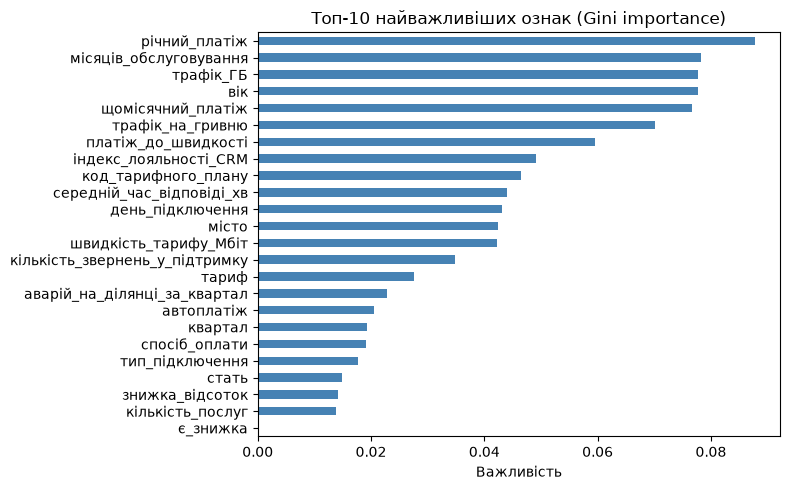

['num__вік' 'num__кількість_послуг' 'num__місяців_обслуговування'
 'num__швидкість_тарифу_Мбіт' 'num__щомісячний_платіж'
 'num__знижка_відсоток' 'num__трафік_ГБ'
 'num__кількість_звернень_у_підтримку' 'num__аварій_на_ділянці_за_квартал'
 'num__середній_час_відповіді_хв' 'num__річний_платіж'
 'num__код_тарифного_плану' 'num__індекс_лояльності_CRM'
 'num__день_підключення' 'num__квартал' 'num__трафік_на_гривню'
 'num__є_знижка' 'num__платіж_до_швидкості' 'cat__стать_ж' 'cat__стать_ч'
 'cat__місто_дрогобич' 'cat__місто_золочів' 'cat__місто_львів'
 'cat__місто_самбір' 'cat__місто_стрий' 'cat__місто_червоноград'
 'cat__тариф_базовий' 'cat__тариф_бізнес' 'cat__тариф_максимальний'
 'cat__тариф_оптимальний' 'cat__тип_підключення_adsl'
 'cat__тип_підключення_оптика' 'cat__тип_підключення_радіо'
 'cat__спосіб_оплати_картка' 'cat__спосіб_оплати_каса'
 'cat__спосіб_оплати_термінал' 'cat__автоплатіж_ні' 'cat__автоплатіж_так']


вік                               0.077717
кількість_послуг                  0.013755
місяців_обслуговування            0.078186
швидкість_тарифу_Мбіт             0.042253
щомісячний_платіж                 0.076701
знижка_відсоток                   0.014169
трафік_ГБ                         0.077734
кількість_звернень_у_підтримку    0.034865
аварій_на_ділянці_за_квартал      0.022851
середній_час_відповіді_хв         0.044049
річний_платіж                     0.087802
код_тарифного_плану               0.046524
індекс_лояльності_CRM             0.049135
день_підключення                  0.043110
квартал                           0.019222
трафік_на_гривню                  0.070168
є_знижка                          0.000000
платіж_до_швидкості               0.059512
стать                             0.007750
стать                             0.007108
місто                             0.005785
місто                             0.006285
місто                             0.008699
місто      

In [96]:
# ----- ВАШ КОД -----
# 1) дістаньте імена після перетворення:
feature_names = model.named_steps['prep'].get_feature_names_out()
importances = model.named_steps['clf'].feature_importances_
# 2) підсумуйте важливості дамі-стовпців до вихідних ознак
raw_names = []
for name in feature_names:
    clean_name = name.split('__')[-1] # прибираємо 'cat__' або 'num__'
    if name.startswith('cat__'):
        # відкидаємо значення категорії після останнього '_' 
        # (якщо в назві самої ознаки є '_', цей підхід збереже її цілою)
        clean_name = clean_name.rsplit('_', 1)[0] 
    raw_names.append(clean_name)
# 3) побудуйте горизонтальну стовпчикову діаграму топ-10
#gini_imp = None
gini_imp = (
    pd.Series(importances, index=raw_names)
    .groupby(level=0)
    .sum()
    .sort_values(ascending=False)

)

print(gini_imp)

# 3) Побудуйте горизонтальну стовпчикову діаграму топ-10
gini_imp.sort_values().plot(kind='barh', figsize=(8, 5), color='steelblue')
plt.title('Топ-10 найважливіших ознак (Gini importance)')
plt.xlabel('Важливість')
plt.tight_layout()
plt.show()
print(feature_names)
pd.Series(importances, index=raw_names)


### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [97]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))
len(perm_imp)

,перестановочна важливість
місяців_обслуговування,0.058130
вік,0.057560
трафік_ГБ,0.032198
річний_платіж,0.012351
трафік_на_гривню,0.009742
аварій_на_ділянці_за_квартал,0.008513
кількість_звернень_у_підтримку,0.005692
місто,0.002540
знижка_відсоток,0.002275
день_підключення,0.002067


24

### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [98]:
# ----- ВАШ КОД: таблиця «ознака | вбудована | перестановочна», відсортована за вбудованою -----
comp = pd.DataFrame({
    'вбудована': gini_imp, 
    'перестановочна': perm_imp
}).sort_values(by='вбудована', ascending=False)
print(gini_imp)
comp


річний_платіж                     0.087802
місяців_обслуговування            0.078186
трафік_ГБ                         0.077734
вік                               0.077717
щомісячний_платіж                 0.076701
трафік_на_гривню                  0.070168
платіж_до_швидкості               0.059512
індекс_лояльності_CRM             0.049135
код_тарифного_плану               0.046524
середній_час_відповіді_хв         0.044049
день_підключення                  0.043110
місто                             0.042352
швидкість_тарифу_Мбіт             0.042253
кількість_звернень_у_підтримку    0.034865
тариф                             0.027516
аварій_на_ділянці_за_квартал      0.022851
автоплатіж                        0.020611
квартал                           0.019222
спосіб_оплати                     0.019174
тип_підключення                   0.017737
стать                             0.014859
знижка_відсоток                   0.014169
кількість_послуг                  0.013755
є_знижка   

,вбудована,перестановочна
річний_платіж,0.087802,0.012351
місяців_обслуговування,0.078186,0.058130
трафік_ГБ,0.077734,0.032198
вік,0.077717,0.057560
щомісячний_платіж,0.076701,-0.003664
трафік_на_гривню,0.070168,0.009742
платіж_до_швидкості,0.059512,-0.000022
індекс_лояльності_CRM,0.049135,-0.000440
код_тарифного_плану,0.046524,-0.006791
середній_час_відповіді_хв,0.044049,-0.000832


In [99]:
FAKE_IMPORTANT = 'щомісячний_платіж'        # назва ознаки
FAKE_IMPORTANT_WHY = 'тому шо перестановочна важливість рахується на тренувальних даних'    # чому вбудована важливість її переоцінює
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: щомісячний_платіж


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [100]:
# ----- ВАШ КОД: кореляційна матриця числових ознак, знайдіть пару з |r| > 0.97 -----
num_cols = [
    col for col in FINAL_X.select_dtypes(include=[np.number]).columns
    if FINAL_X[col].nunique() > 2
]
corr_matrix = FINAL_X[num_cols].corr()
corr_matrix


,вік,кількість_послуг,місяців_обслуговування,швидкість_тарифу_Мбіт,щомісячний_платіж,знижка_відсоток,трафік_ГБ,кількість_звернень_у_підтримку,аварій_на_ділянці_за_квартал,середній_час_відповіді_хв,річний_платіж,код_тарифного_плану,індекс_лояльності_CRM,день_підключення,квартал,трафік_на_гривню,платіж_до_швидкості
вік,1.000000,-0.033122,0.012265,-0.051567,-0.037733,0.032594,0.040667,-0.015129,-0.012470,-0.021579,-0.023861,0.029575,-0.003766,-0.045851,0.021356,0.009080,0.026607
кількість_послуг,-0.033122,1.000000,0.054852,0.064829,0.429315,0.048613,-0.021674,-0.027821,0.018051,-0.026753,0.432950,0.031039,-0.012252,0.041546,0.051052,-0.127473,0.151756
місяців_обслуговування,0.012265,0.054852,1.000000,-0.009868,0.008923,-0.044346,-0.006893,0.024668,-0.008173,-0.046050,0.010349,-0.012135,-0.003199,-0.041262,0.016068,0.050277,0.038976
швидкість_тарифу_Мбіт,-0.051567,0.064829,-0.009868,1.000000,0.721463,0.046273,0.017392,0.012647,-0.005225,-0.012734,0.719383,0.024823,0.061564,0.015820,0.091465,-0.084772,-0.660365
щомісячний_платіж,-0.037733,0.429315,0.008923,0.721463,1.000000,0.064295,0.020657,-0.014418,0.036051,-0.017165,0.999135,0.036885,0.037952,0.028959,0.046510,-0.127437,-0.351535
знижка_відсоток,0.032594,0.048613,-0.044346,0.046273,0.064295,1.000000,0.057275,0.023634,-0.003830,-0.017163,0.056618,0.027184,-0.007998,-0.025169,0.067505,-0.690239,0.026821
трафік_ГБ,0.040667,-0.021674,-0.006893,0.017392,0.020657,0.057275,1.000000,-0.012619,-0.002264,0.013748,0.025428,0.007814,0.011677,-0.005031,0.007359,0.150518,0.010726
кількість_звернень_у_підтримку,-0.015129,-0.027821,0.024668,0.012647,-0.014418,0.023634,-0.012619,1.000000,-0.034318,0.037321,-0.024821,-0.038757,0.052221,-0.000174,0.033636,-0.004829,-0.034154
аварій_на_ділянці_за_квартал,-0.012470,0.018051,-0.008173,-0.005225,0.036051,-0.003830,-0.002264,-0.034318,1.000000,-0.016383,0.025275,0.031700,-0.008327,-0.015530,0.025173,-0.001965,-0.010435
середній_час_відповіді_хв,-0.021579,-0.026753,-0.046050,-0.012734,-0.017165,-0.017163,0.013748,0.037321,-0.016383,1.000000,-0.027158,-0.016628,0.002397,0.044579,0.024030,-0.016219,-0.026179


In [101]:
DUP_PAIR = ['річний_платіж', 'щомісячний_платіж']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# ----- ВАШ КОД: приберіть DUP_PAIR[1], навчіть заново, порахуйте перестановочну -----
# і виведіть важливість DUP_PAIR[0] без пари
FINAL_X1 = FINAL_X.drop(columns=["щомісячний_платіж"])
Xtr, Xte, ytr, yte = train_test_split(FINAL_X1, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X1, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.5f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')
auc5.mean()

perm1 = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp1 = pd.Series(perm1.importances_mean, index=FINAL_X1.columns).sort_values(ascending=False)
display(perm_imp1.to_frame('перестановочна важливість'))
len(perm_imp1)


у повній моделі:
   річний_платіж                +0.0124
   щомісячний_платіж            -0.0037
модель навчена; AUC на відкладеній частині 0.80337
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


,перестановочна важливість
місяців_обслуговування,0.058650
вік,0.057415
трафік_ГБ,0.029299
річний_платіж,0.022894
трафік_на_гривню,0.008245
кількість_звернень_у_підтримку,0.007889
швидкість_тарифу_Мбіт,0.005113
день_підключення,0.002260
тип_підключення,0.001842
аварій_на_ділянці_за_квартал,0.001736


23

In [102]:
DUP_EXPLANATION = 'важливість збільшилась'
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

важливість збільшилась


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

['місяців_обслуговування', 'вік', 'трафік_ГБ']

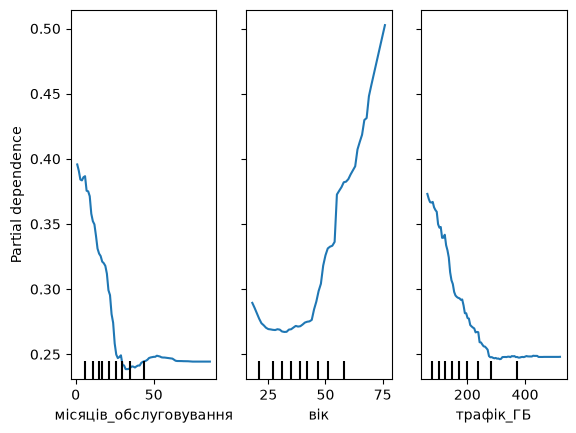

In [103]:
from sklearn.inspection import PartialDependenceDisplay
f = perm_imp1.to_frame('перестановочна важливість').sort_values('перестановочна важливість',ascending=False)[:3].index.to_list()

# ----- ВАШ КОД -----
PartialDependenceDisplay.from_estimator(model, Xte, features=f, kind='average')
# Увага: ознака з пропусками дасть порожню сітку — беріть ознаки без NaN
# або будуйте PDP на підвибірці, де ця ознака заповнена.
f

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

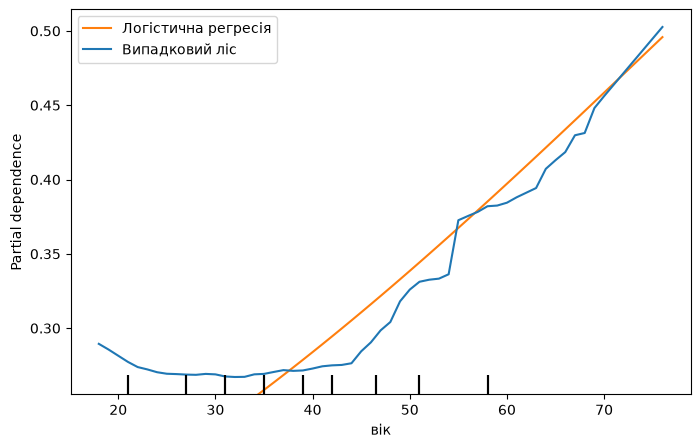

In [104]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

# ----- ВАШ КОД: один рисунок, дві криві — ліс і логістична регресія -----
cl = make_pipe(FINAL_X1, logreg()).fit(Xtr, ytr)

fig, ax = plt.subplots(figsize=(8, 5))

# 1. Зберігаємо результат першого виклику в змінну disp
disp = PartialDependenceDisplay.from_estimator(
    cl, Xte, ax=ax, features=[NONLINEAR_FEATURE], kind='average',
    line_kw={'label': 'Логістична регресія', 'color': 'tab:orange'}
)

# 2. Передаємо disp.axes_ замість ax
PartialDependenceDisplay.from_estimator(
    model, Xte, ax=disp.axes_, features=[NONLINEAR_FEATURE], kind='average',
    line_kw={'label': 'Випадковий ліс', 'color': 'tab:blue'}
)

ax.legend()
plt.show()


In [105]:
NONLINEAR_MEANING = '18 років частіше йдуть,чим старше тим менше йдуть а потім в 40 років більше йдуть'     # що означає ця форма змістовно, мовою предметної області
NONLINEAR_FIX = 'розбити вік на вікові категорії'         # яку ознаку треба сконструювати, щоб лінійна модель це побачила
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

18 років частіше йдуть,чим старше тим менше йдуть а потім в 40 років більше йдуть
розбити вік на вікові категорії


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

модель навчена; AUC на відкладеній частині 0.80296
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


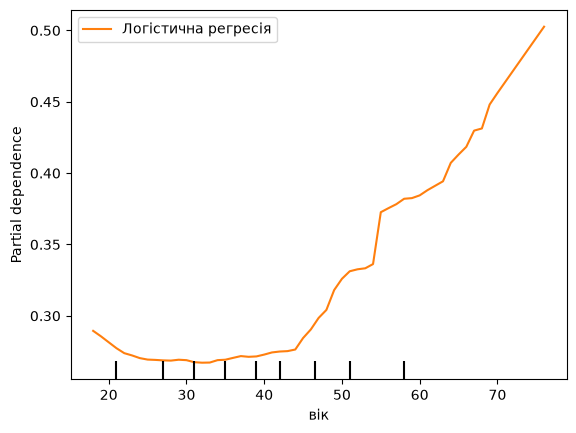

In [113]:
# ----- ВАШ КОД -----
# 1) зчитайте з графіка значення, при якому ризик мінімальний;
disp = PartialDependenceDisplay.from_estimator(
    model, Xte, features=[NONLINEAR_FEATURE], kind='average',
    line_kw={'label': 'Логістична регресія', 'color': 'tab:orange'}
)
grid_values = disp.pd_results[0]['grid_values'][0]
pdp_values = disp.pd_results[0]['average'][0]
min_risk_val = grid_values[np.argmin(pdp_values)]
min_risk_val
# 2) додайте ознаку «квадрат відхилення від цього значення»;
# 3) парне порівняння логістичної регресії з нею і без неї.FINAL_X1 = FINAL_X.drop(columns=["щомісячний_платіж"])
x_min = min_risk_val  

# Створюємо копії датасетів, щоб не змінити початкові таблиці для порівняння
Xtr_new = Xtr.copy()
Xte_new = Xte.copy()

# Додаємо нову колонку: (x - x_min)²
new_feature = f"{NONLINEAR_FEATURE}_sq_dev"
Xtr_new[new_feature] = (Xtr_new[NONLINEAR_FEATURE] - x_min) ** 2
Xte_new[new_feature] = (Xte_new[NONLINEAR_FEATURE] - x_min) ** 2
auc_hold = roc_auc_score(yte, cl.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.5f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

In [107]:

auc_hold1 = roc_auc_score(yte, cl.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.5f' % auc_hold1)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')
QUAD_GAIN = auc_hold1-auc_hold     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

модель навчена; AUC на відкладеній частині 0.80296
(одне число з широкого розподілу — див. розділ 5.5 конспекту)
приріст від сконструйованої ознаки: +0.0000


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

Index(['вік', 'стать', 'місто', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'знижка_відсоток', 'трафік_ГБ',
       'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'код_тарифного_плану', 'індекс_лояльності_CRM', 'день_підключення', 'квартал',
       'трафік_на_гривню', 'є_знижка', 'платіж_до_швидкості'],
      dtype='str')


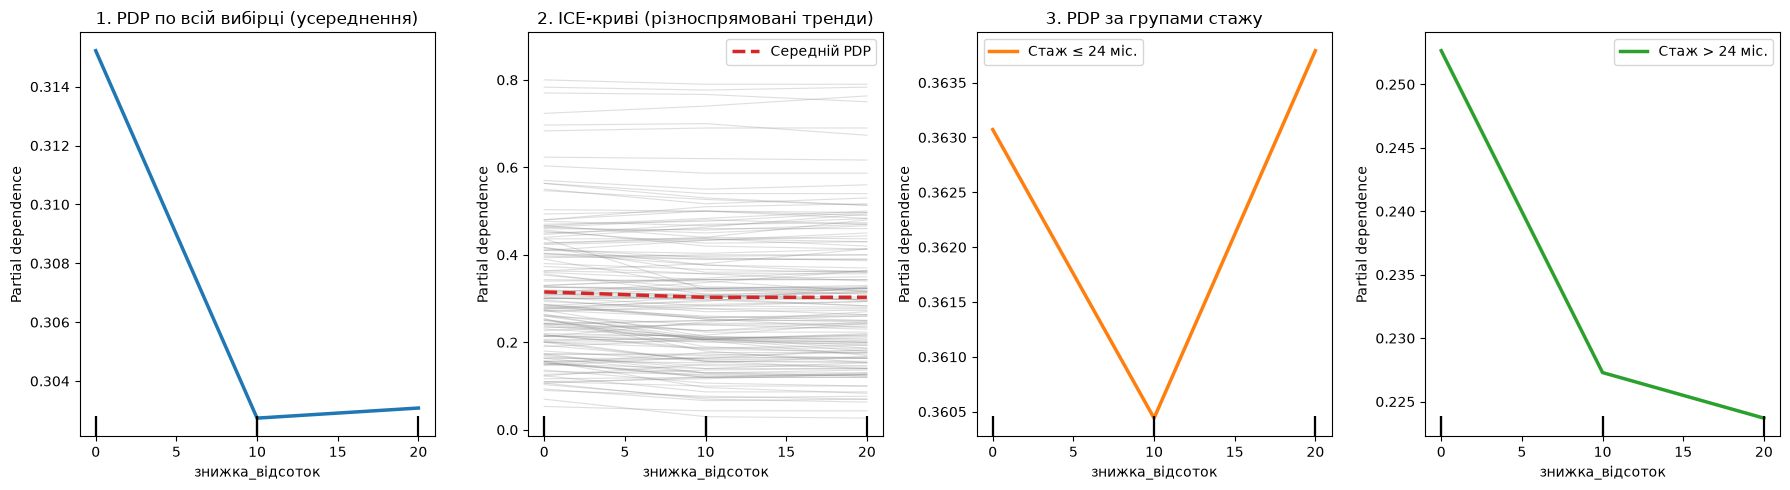

In [122]:
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay

# Переконайтеся, що використовується актуальна модель (наприклад, model або tree_model / gbm)
# та відповідна вибірка Xte (де присутні колонки 'знижка_відсоток' і 'стаж_обслуговування')

fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharey=True)

# 1. Звичайний PDP по всій вибірці
PartialDependenceDisplay.from_estimator(
    model,
    Xte,
    features=['знижка_відсоток'],
    kind='average',
    ax=axes[0],
    line_kw={'color': 'tab:blue', 'linewidth': 2.5}
)
axes[0].set_title('1. PDP по всій вибірці (усереднення)')
axes[0].grid(True, alpha=0.3)

# 2. ICE-криві (kind='individual' або 'both' для відображення середнього поверх індивідуальних)
PartialDependenceDisplay.from_estimator(
    model,
    Xte,
    features=['знижка_відсоток'],
    kind='both',
    subsample=150,  # обмежуємо кількість ліній для читабельності графіка
    random_state=42,
    ax=axes[1],
    ice_lines_kw={'color': 'tab:gray', 'alpha': 0.25, 'linewidth': 0.8},
    pd_line_kw={'color': 'tab:red', 'linewidth': 2.5, 'label': 'Середній PDP'}
)
axes[1].set_title('2. ICE-криві (різноспрямовані тренди)')
axes[1].grid(True, alpha=0.3)
print(Xte.columns)
# 3. Окремі PDP для двох підвибірок за стажем обслуговування (<= 24 та > 24 міс.)
# (Замініть 'стаж_обслуговування' на точну назву колонки у вашому датасеті, якщо вона відрізняється)
tenure_col = 'місяців_обслуговування'
mask_short = Xte[tenure_col] <= 24
mask_long = Xte[tenure_col] > 24

PartialDependenceDisplay.from_estimator(
    model,
    Xte[mask_short],
    features=['знижка_відсоток'],
    kind='average',
    ax=axes[2],
    line_kw={'color': 'tab:orange', 'linewidth': 2.5, 'label': 'Стаж ≤ 24 міс.'}
)

PartialDependenceDisplay.from_estimator(
    model,
    Xte[mask_long],
    features=['знижка_відсоток'],
    kind='average',
    ax=axes[3],
    line_kw={'color': 'tab:green', 'linewidth': 2.5, 'label': 'Стаж > 24 міс.'}
)
axes[2].set_title('3. PDP за групами стажу')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
# ----- ВАШ КОД: пункт 3, дві криві на одному рисунку -----
#partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')

ValueError: cannot reshape array of size 2 into shape (2,2)

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [110]:
# ----- ВАШ КОД: зведена таблиця «знижка x група стажу» -> частка відтоку і розмір групи -----

In [124]:
INTERACTION_FOUND = 'не знаю'     # опишіть, що робить знижка в кожній із двох груп
BUSINESS_ACTION = 'не знаю'       # що з цього випливає для відділу утримання
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

не знаю
не знаю


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [126]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 37)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

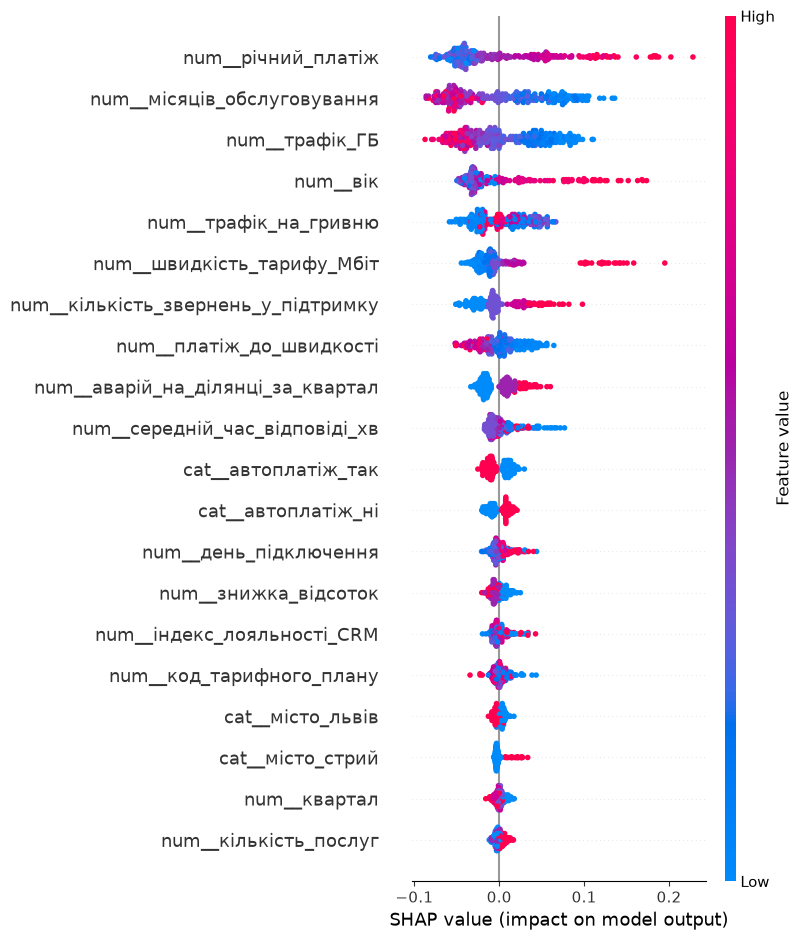

In [128]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names)

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [137]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

# Отримуємо SHAP-значення для обраного клієнта (sv1 вже є ndarray)
vals = sv1[idx]

# Якщо масив тривимірний (зразки, ознаки, класи) — беремо внесок для класу 1
if vals.ndim == 2:
    vals = vals[:, 1]

names = Xte.columns

top3_idx = np.argsort(np.abs(vals))[::-1][:3]
for i in top3_idx:
    print(f"{names[i]}: {vals[i]:+.4f}")


ризик клієнта: 0.827
швидкість_тарифу_Мбіт: +0.2021
тариф: +0.1427
середній_час_відповіді_хв: +0.0656


In [138]:
EXPLANATION_FOR_MANAGER = ' '
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [139]:
SHAP_NOT_CAUSAL_FEATURE = 'кількість_звернень'  # підставте точну назву колонки з Xte.columns
SHAP_NOT_CAUSAL_WHY = (
    "Це ознака-наслідок (симптом), а не першопричина відтоку: клієнт звертається в підтримку, "
    "бо вже має проблему з якістю сервісу або тарифом. Штучно заблокувати чи зменшити лічильник звернень "
    "не вирішить проблему клієнта і не втримає його від уходу."
)
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)


кількість_звернень — Це ознака-наслідок (симптом), а не першопричина відтоку: клієнт звертається в підтримку, бо вже має проблему з якістю сервісу або тарифом. Штучно заблокувати чи зменшити лічильник звернень не вирішить проблему клієнта і не втримає його від уходу.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [140]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",щомісячний_платіж,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",річний_платіж + щомісячний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",кількість_звернень,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [141]:
FIFTH_MISTAKE = '--------------------------------------------------------------------------------------'
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

--------------------------------------------------------------------------------------


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [ ]:
# ----- ВАШ КОД -----
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100
lift = None

In [ ]:
LIFT_MEANING = ''    # що число lift означає для бізнесу, одним реченням
assert LIFT_MEANING
print(LIFT_MEANING)

> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [ ]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [ ]:
REPORT = '''
1.
2.
3.
4.
5.
6.
7.
8.
9.
10.
11.

Декларація про використання ШІ:
'''
print(REPORT)

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.